# Assignment 7 — Section 1: Graph Neural Networks

In [ ]:
!pip install -q torch_geometric

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import negative_sampling, to_networkx
from sklearn.metrics import roc_auc_score, average_precision_score

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 1.1 Message passing on a toy graph

In [2]:
edge_index = torch.tensor([[0, 1, 1, 2, 3, 3],
                           [1, 0, 2, 1, 2, 0]], dtype=torch.long)
x = torch.tensor([[1, 2, 3], [4, 5, 6],
                  [7, 8, 9], [10, 11, 12]], dtype=torch.float)
data = Data(x=x, edge_index=edge_index)

### (a) Graph structure

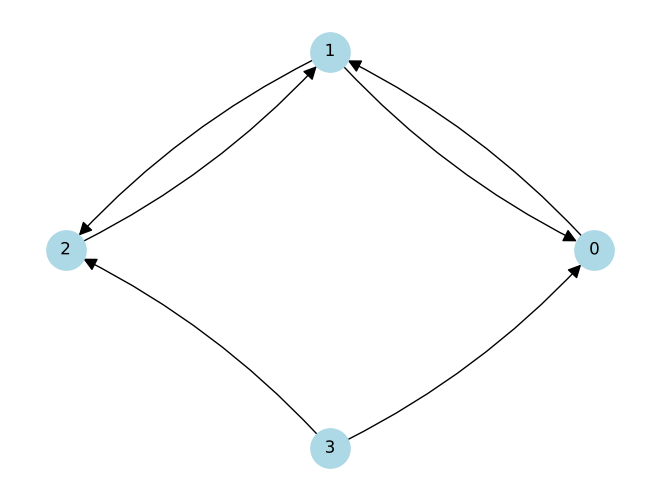

Edges without a reverse edge: [(3, 0), (3, 2)]


In [3]:
G = to_networkx(data, to_undirected=False)
nx.draw(G, pos=nx.circular_layout(G), with_labels=True, node_color='lightblue',
        node_size=800, arrowsize=20, connectionstyle='arc3,rad=0.1')
plt.show()

edges = set(map(tuple, edge_index.t().tolist()))
print('Edges without a reverse edge:', sorted(e for e in edges if e[::-1] not in edges))

Not undirected. Edges 3→2 and 3→0 have no reverse, so node 3 only sends messages and receives none.

### (b) One GCN layer by hand

In [4]:
conv = GCNConv(3, 4)

# A[i, j] = 1 if there is an edge j -> i (node i receives from j)
A = torch.zeros(4, 4)
A[edge_index[1], edge_index[0]] = 1
A_tilde = A + torch.eye(4)                     # add self-loops
d = A_tilde.sum(dim=1)                         # in-degree (incl. self-loop)
A_hat = torch.diag(d.pow(-0.5)) @ A_tilde @ torch.diag(d.pow(-0.5))
print(A_hat)

W = conv.lin.weight                            # shape (4, 3)
manual = A_hat @ (x @ W.t()) + conv.bias
layer = conv(x, edge_index)

print('Match:', torch.allclose(manual, layer, atol=1e-6))

tensor([[0.3333, 0.3333, 0.0000, 0.5774],
        [0.3333, 0.3333, 0.3333, 0.0000],
        [0.0000, 0.3333, 0.3333, 0.5774],
        [0.0000, 0.0000, 0.0000, 1.0000]])
Match: True


### (c) Training

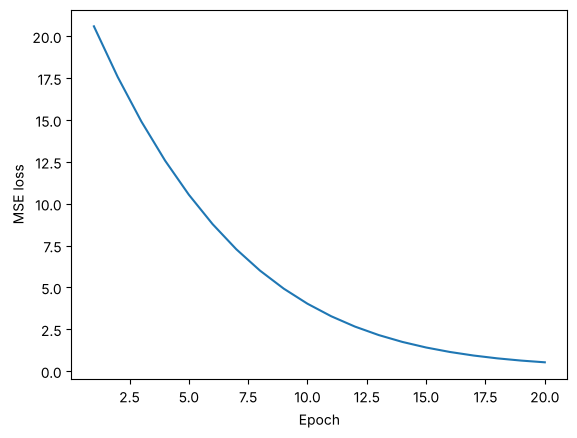

In [5]:
class GCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(3, 4)
        self.conv2 = GCNConv(4, 2)

    def forward(self, data):
        x = torch.relu(self.conv1(data.x, data.edge_index))
        return self.conv2(x, data.edge_index)

model = GCN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()
target = torch.tensor([[0, 1], [1, 0], [0, 1], [1, 0]], dtype=torch.float)

losses = []
model.train()
for epoch in range(20):
    optimizer.zero_grad()
    loss = criterion(model(data), target)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

plt.plot(range(1, 21), losses)
plt.xlabel('Epoch'); plt.ylabel('MSE loss'); plt.show()

## 1.2 Link prediction on Cora

In [6]:
dataset = Planetoid(root='./data', name='Cora')
data = dataset[0]

split = RandomLinkSplit(num_val=0.05, num_test=0.10, is_undirected=True,
                        add_negative_train_samples=False)
train_data, val_data, test_data = split(data)

### (d) Data split

In [7]:
print(f'Train: {train_data.edge_label_index.size(1)} positive edges (negatives sampled every epoch)')
for name, d in [('Val', val_data), ('Test', test_data)]:
    pos = int((d.edge_label == 1).sum()); neg = int((d.edge_label == 0).sum())
    print(f'{name}: {pos} positive, {neg} negative')

Train: 4488 positive edges (negatives sampled every epoch)
Val: 263 positive, 263 negative
Test: 527 positive, 527 negative


### (e) Model

In [8]:
class LinkPredGCN(nn.Module):
    def __init__(self, in_dim, hid_dim=16, out_dim=16):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hid_dim)
        self.conv2 = GCNConv(hid_dim, out_dim)
        self.lin = nn.Linear(out_dim, 1)

    def encode(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)

    def decode(self, z, edge_label_index):
        src, dst = edge_label_index
        return self.lin(z[src] * z[dst]).squeeze(-1)   # logit

### (f) Training with negative sampling

Best validation loss 0.4119 at epoch 37


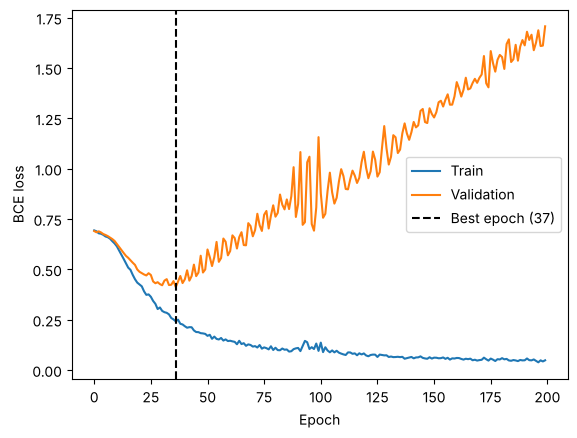

<All keys matched successfully>

In [9]:
model = LinkPredGCN(dataset.num_features).to(device)
train_data, val_data, test_data = train_data.to(device), val_data.to(device), test_data.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

def train_step():
    model.train()
    optimizer.zero_grad()
    z = model.encode(train_data.x, train_data.edge_index)
    pos = model.decode(z, train_data.edge_label_index)
    neg_idx = negative_sampling(train_data.edge_index, train_data.num_nodes,
                                num_neg_samples=pos.size(0))   # fresh negatives
    neg = model.decode(z, neg_idx)
    logits = torch.cat([pos, neg])
    labels = torch.cat([torch.ones_like(pos), torch.zeros_like(neg)])
    loss = F.binary_cross_entropy_with_logits(logits, labels)
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def val_loss():
    model.eval()
    z = model.encode(val_data.x, val_data.edge_index)
    logits = model.decode(z, val_data.edge_label_index)
    return F.binary_cross_entropy_with_logits(logits, val_data.edge_label).item()

train_losses, val_losses = [], []
best_val, best_state = float('inf'), None
for epoch in range(1, 201):
    train_losses.append(train_step())
    val_losses.append(val_loss())
    if val_losses[-1] < best_val:                      # early stopping: keep best epoch
        best_val, best_epoch = val_losses[-1], epoch
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

print(f'Best validation loss {best_val:.4f} at epoch {best_epoch}')
plt.plot(train_losses, label='Train')
plt.plot(val_losses, label='Validation')
plt.axvline(best_epoch - 1, color='k', ls='--', label=f'Best epoch ({best_epoch})')
plt.xlabel('Epoch'); plt.ylabel('BCE loss'); plt.legend(); plt.show()

model.load_state_dict(best_state)

### (g) Evaluation

In [10]:
model.eval()
with torch.no_grad():
    z = model.encode(test_data.x, test_data.edge_index)   # train + val edges for message passing
    probs = torch.sigmoid(model.decode(z, test_data.edge_label_index)).cpu()
y = test_data.edge_label.cpu()

print(f'Test ROC-AUC: {roc_auc_score(y, probs):.4f}')
print(f'Test AP:      {average_precision_score(y, probs):.4f}')

Test ROC-AUC: 0.9027
Test AP:      0.9047


### Discussion
Negative edges are needed because with positive edges alone, the loss is minimised by scoring every pair as an edge.